<a href="https://colab.research.google.com/github/ericrulz643/Insurance-Risk-Pricing-Analysis/blob/main/notebooks/insurance_risk_pricing_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Python is working!")
print(2 + 2)

Python is working!
4


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving freMTPL2freq.csv to freMTPL2freq.csv
Saving freMTPL2sev.csv to freMTPL2sev.csv


In [4]:
import pandas as pd

freq = pd.read_csv("freMTPL2freq.csv")
sev = pd.read_csv("freMTPL2sev.csv")

print("Frequency dataset:", freq.shape)
print("Severity dataset:", sev.shape)

display(freq.head())
display(sev.head())

Frequency dataset: (678013, 12)
Severity dataset: (26639, 2)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [5]:
print("FREQUENCY DATA")
print("Shape:", freq.shape)
print("Columns:", freq.columns.tolist())
print()
print("Missing values:")
display(freq.isnull().sum())

print("\nSEVERITY DATA")
print("Shape:", sev.shape)
print("Columns:", sev.columns.tolist())
print()
print("Missing values:")
display(sev.isnull().sum())

FREQUENCY DATA
Shape: (678013, 12)
Columns: ['IDpol', 'ClaimNb', 'Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Area', 'Density', 'Region']

Missing values:


,0
IDpol,0
ClaimNb,0
Exposure,0
VehPower,0
VehAge,0
DrivAge,0
BonusMalus,0
VehBrand,0
VehGas,0
Area,0



SEVERITY DATA
Shape: (26639, 2)
Columns: ['IDpol', 'ClaimAmount']

Missing values:


,0
IDpol,0
ClaimAmount,0


In [6]:
# Summary statistics for numerical variables
print("FREQUENCY DATA SUMMARY")
display(freq.describe().round(2))

print("SEVERITY DATA SUMMARY")
display(sev["ClaimAmount"].describe().round(2))

FREQUENCY DATA SUMMARY


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,678013.00,678013.00,678013.00,678013.00,678013.00,678013.00,678013.00,678013.00
mean,2621856.92,0.05,0.53,6.45,7.04,45.50,59.76,1792.42
std,1641782.75,0.24,0.36,2.05,5.67,14.14,15.64,3958.65
min,1.00,0.00,0.00,4.00,0.00,18.00,50.00,1.00
25%,1157951.00,0.00,0.18,5.00,2.00,34.00,50.00,92.00
50%,2272152.00,0.00,0.49,6.00,6.00,44.00,50.00,393.00
75%,4046274.00,0.00,0.99,7.00,11.00,55.00,64.00,1658.00
max,6114330.00,16.00,2.01,15.00,100.00,100.00,230.00,27000.00


SEVERITY DATA SUMMARY


,ClaimAmount
count,26639.00
mean,2278.54
std,29297.48
min,1.00
25%,686.81
50%,1172.00
75%,1228.08
max,4075400.56


In [7]:
total_claims = freq["ClaimNb"].sum()
total_exposure = freq["Exposure"].sum()
policies_with_claims = (freq["ClaimNb"] > 0).sum()

claim_frequency = total_claims / total_exposure

print(f"Number of policy records: {len(freq):,}")
print(f"Total claims recorded: {total_claims:,}")
print(f"Total exposure (policy-years): {total_exposure:,.2f}")
print(f"Policies with at least one claim: {policies_with_claims:,}")
print(f"Overall claim frequency: {claim_frequency:.4f} claims per policy-year")
print(f"Equivalent claims per 100 policy-years: {100 * claim_frequency:.2f}")

Number of policy records: 678,013
Total claims recorded: 36,102
Total exposure (policy-years): 358,499.45
Policies with at least one claim: 34,060
Overall claim frequency: 0.1007 claims per policy-year
Equivalent claims per 100 policy-years: 10.07


In [8]:
# Group drivers into age bands
age_bins = [17, 25, 35, 45, 55, 65, 101]
age_labels = [
    "18–24", "25–34", "35–44",
    "45–54", "55–64", "65+"
]

freq["AgeGroup"] = pd.cut(
    freq["DrivAge"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Summarize claims and exposure by age group
age_analysis = (
    freq.groupby("AgeGroup", observed=False)
    .agg(
        Policies=("IDpol", "size"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

age_analysis["ClaimFrequency"] = (
    age_analysis["Claims"] / age_analysis["Exposure"]
)

age_analysis["ClaimsPer100PolicyYears"] = (
    100 * age_analysis["ClaimFrequency"]
)

display(age_analysis.round(4))

,Policies,Claims,Exposure,ClaimFrequency,ClaimsPer100PolicyYears
AgeGroup,,,,,
18–24,30198,2364,12489.1611,0.1893,18.9284
25–34,140947,6396,64598.6144,0.0990,9.9011
35–44,170578,8145,87391.4525,0.0932,9.3201
45–54,164034,9513,89852.7465,0.1059,10.5873
55–64,99094,5124,56176.9511,0.0912,9.1212
65+,73162,4560,47990.5198,0.0950,9.5019


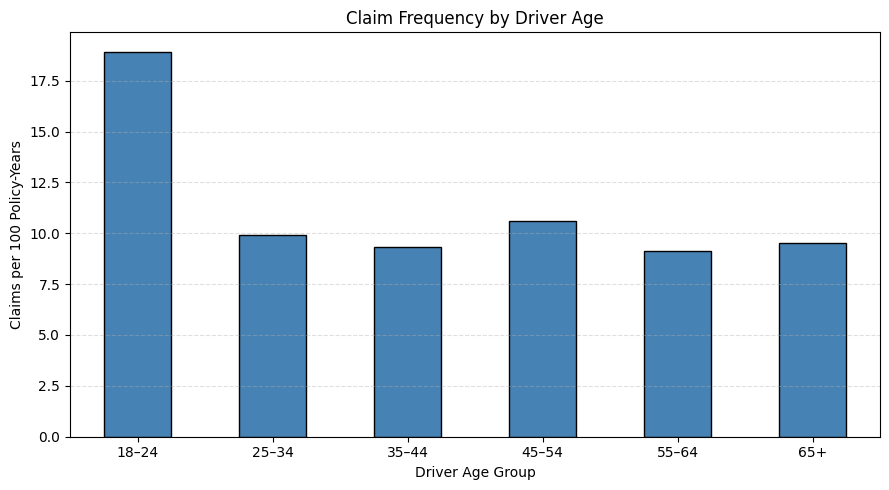

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

age_analysis["ClaimsPer100PolicyYears"].plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Claim Frequency by Driver Age")
plt.xlabel("Driver Age Group")
plt.ylabel("Claims per 100 Policy-Years")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [10]:
# Group vehicles by age
veh_age_bins = [-1, 1, 5, 10, 15, 20, float("inf")]
veh_age_labels = [
    "0–1", "2–5", "6–10", "11–15", "16–20", "21+"
]

freq["VehAgeGroup"] = pd.cut(
    freq["VehAge"],
    bins=veh_age_bins,
    labels=veh_age_labels
)

# Calculate claims and exposure by vehicle age
veh_age_analysis = (
    freq.groupby("VehAgeGroup", observed=False)
    .agg(
        Policies=("IDpol", "size"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

veh_age_analysis["ClaimsPer100PolicyYears"] = (
    100 * veh_age_analysis["Claims"] / veh_age_analysis["Exposure"]
)

display(veh_age_analysis.round(3))

,Policies,Claims,Exposure,ClaimsPer100PolicyYears
VehAgeGroup,,,,
0–1,129023,8136,49468.566,16.447
2–5,191614,9511,101747.613,9.348
6–10,171594,9846,99008.916,9.945
11–15,134063,6648,77990.975,8.524
16–20,43397,1685,25136.159,6.703
21+,8322,276,5147.216,5.362


In [11]:
# Create population-density groups
freq["DensityGroup"] = pd.qcut(
    freq["Density"],
    q=5,
    duplicates="drop"
)

density_analysis = (
    freq.groupby("DensityGroup", observed=True)
    .agg(
        Policies=("IDpol", "size"),
        Claims=("ClaimNb", "sum"),
        Exposure=("Exposure", "sum")
    )
)

density_analysis["ClaimsPer100PolicyYears"] = (
    100 * density_analysis["Claims"] / density_analysis["Exposure"]
)

display(density_analysis.round(3))

,Policies,Claims,Exposure,ClaimsPer100PolicyYears
DensityGroup,,,,
"(0.999, 67.0]",137340,6753,81409.010,8.295
"(67.0, 214.0]",134178,6743,74104.380,9.099
"(214.0, 716.0]",135398,7091,72041.132,9.843
"(716.0, 2715.0]",137845,7855,69486.204,11.304
"(2715.0, 27000.0]",133252,7660,61458.721,12.464


In [4]:
print("Number of individual claims:", len(sev))
print("Total claim amount:", round(sev["ClaimAmount"].sum(), 2))
print("Average claim amount:", round(sev["ClaimAmount"].mean(), 2))
print("Median claim amount:", round(sev["ClaimAmount"].median(), 2))
print("Largest claim amount:", round(sev["ClaimAmount"].max(), 2))

display(sev["ClaimAmount"].describe().round(2))

Number of individual claims: 26639
Total claim amount: 60697930.68
Average claim amount: 2278.54
Median claim amount: 1172.0
Largest claim amount: 4075400.56


,ClaimAmount
count,26639.00
mean,2278.54
std,29297.48
min,1.00
25%,686.81
50%,1172.00
75%,1228.08
max,4075400.56


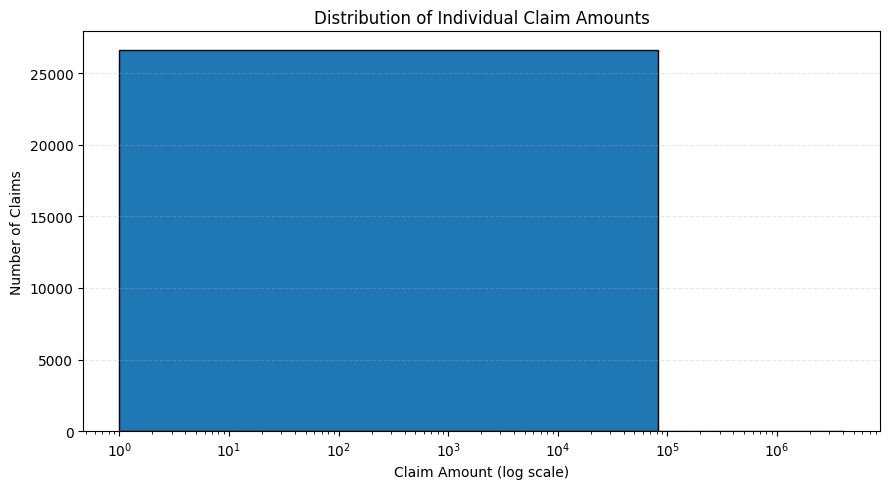

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(sev["ClaimAmount"], bins=50, edgecolor="black")
plt.xscale("log")

plt.title("Distribution of Individual Claim Amounts")
plt.xlabel("Claim Amount (log scale)")
plt.ylabel("Number of Claims")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

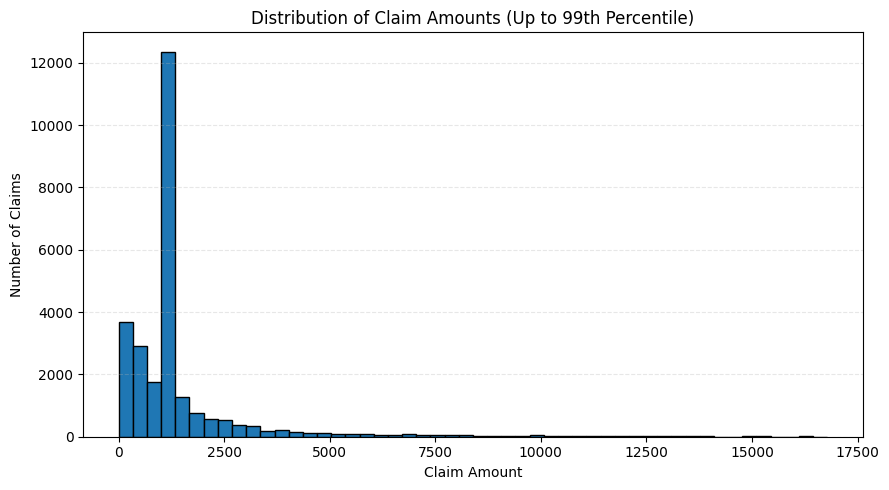

99th percentile: 16,793.70


In [8]:
upper_limit = sev["ClaimAmount"].quantile(0.99)

plt.figure(figsize=(9, 5))

plt.hist(
    sev.loc[sev["ClaimAmount"] <= upper_limit, "ClaimAmount"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Claim Amounts (Up to 99th Percentile)")
plt.xlabel("Claim Amount")
plt.ylabel("Number of Claims")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"99th percentile: {upper_limit:,.2f}")

In [9]:
threshold = sev["ClaimAmount"].quantile(0.99)

largest_claims = sev[sev["ClaimAmount"] > threshold]

share_of_total = (
    largest_claims["ClaimAmount"].sum()
    / sev["ClaimAmount"].sum()
    * 100
)

print("Number of claims in the largest 1% group:", len(largest_claims))
print(f"Share of total claim amount: {share_of_total:.2f}%")

Number of claims in the largest 1% group: 267
Share of total claim amount: 37.96%
